# Understanding Bias and Variance in Machine Learning



Before diving into ensemble methods like Bagging, Random Forests, and Boosting, it’s essential to understand two core sources of error in machine learning models: **Bias** and **Variance**.

## The Total Error
The total prediction error of a model is composed of:
- **Bias²** (error from wrong assumptions)
- **Variance** (error from sensitivity to small fluctuations in training set)
- **Irreducible error** (noise in data)

### Total Expected Error:
$$
\text{Error} = \text{Bias}^2 + \text{Variance} + \text{Irreducible Error}
$$


## Bias

**Bias** refers to the error due to **overly simplistic assumptions** in the learning algorithm.

- High bias leads to **underfitting**.
- Model misses the underlying patterns in the data.
- Occurs when model is too simple (e.g., Linear model on non-linear data).

### Example:
Predicting house prices with a linear model that doesn't account for non-linear interactions (like location, amenities, etc.)

### Visual Cue:
A model with high bias will predict almost the same function, regardless of the training data.

## Variance

**Variance** refers to the error due to **model complexity** and sensitivity to small fluctuations in training data.

- High variance leads to **overfitting**.
- The model captures noise as if it were signal.
- Happens when model is too complex relative to the dataset size.

### Example:
Using a deep decision tree or high-degree polynomial that fits training data perfectly but performs poorly on new data.

### Visual Cue:
A model with high variance gives very different results if trained on different subsets of the data.


## Bias-Variance Tradeoff

The goal in machine learning is to find a **balance** between Bias and Variance:

- **Low Bias + Low Variance** = Ideal (but hard to achieve)
- **High Bias + Low Variance** = Underfitting
- **Low Bias + High Variance** = Overfitting

### Tradeoff Diagram:
![Bias-Variance Tradeoff](https://upload.wikimedia.org/wikipedia/commons/9/9f/Bias_and_variance_contributing_to_total_error.svg)

> Ensemble methods like Bagging and Boosting are designed to address this tradeoff by reducing **variance**, **bias**, or both.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, mean_squared_error, roc_auc_score, roc_curve)
from sklearn.model_selection import (KFold, RepeatedStratifiedKFold, cross_val_score,
                                     learning_curve, train_test_split, validation_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")

## Synthetic data with a known truth

Because the generating function is known, $f(x) = x^3$ with Gaussian noise of standard deviation 0.1, we can later measure bias and variance **exactly by simulation** instead of only describing them. Training points are shuffled into a train set (30 points) and a separate test set (200 fresh points).

In [2]:
rng = np.random.default_rng(42)
NOISE = 0.1
f_true = lambda x: x ** 3

def make_data(n, rng):
    x = np.sort(rng.uniform(-1, 1, size=(n, 1)), axis=0)
    return x, f_true(x) + NOISE * rng.normal(size=(n, 1))

X, y = make_data(30, rng)            # training data
X_val, y_val = make_data(200, rng)   # fresh data, used only to measure generalisation

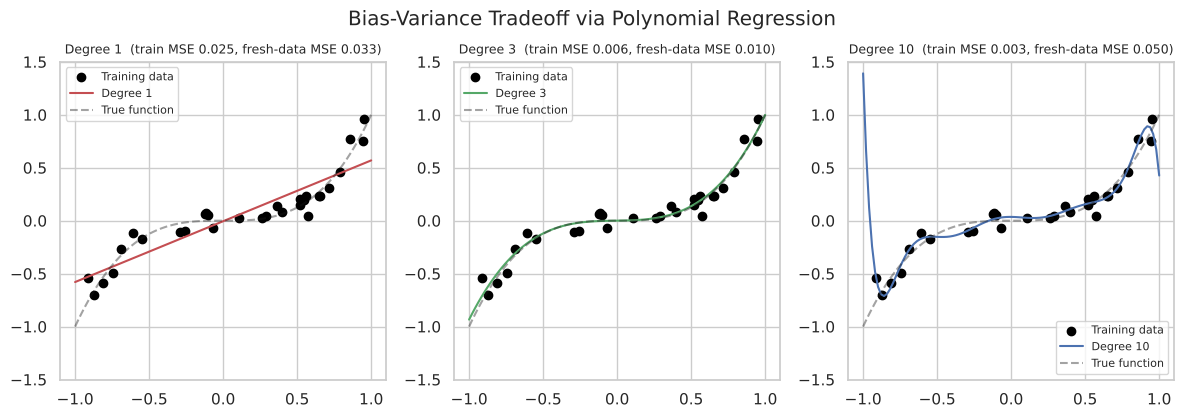

In [3]:
degrees = [1, 3, 10]
colors = ['r', 'g', 'b']
X_plot = np.linspace(-1, 1, 100).reshape(-1, 1)
plt.figure(figsize=(12, 4))

for i, d in enumerate(degrees):
    model = make_pipeline(PolynomialFeatures(degree=d), LinearRegression()).fit(X, y)
    mse_tr = mean_squared_error(y, model.predict(X))
    mse_te = mean_squared_error(y_val, model.predict(X_val))

    plt.subplot(1, 3, i+1)
    plt.scatter(X, y, color='black', label='Training data')
    plt.plot(X_plot, model.predict(X_plot), color=colors[i], label=f'Degree {d}')
    plt.plot(X_plot, f_true(X_plot), 'k--', alpha=0.4, label='True function')
    plt.title(f'Degree {d}  (train MSE {mse_tr:.3f}, fresh-data MSE {mse_te:.3f})', fontsize=9)
    plt.ylim(-1.5, 1.5)
    plt.legend(fontsize=8)

plt.tight_layout()
plt.suptitle('Bias-Variance Tradeoff via Polynomial Regression', y=1.04)
plt.show()

## Measuring bias and variance by simulation

Draw many independent training sets (30 points each) from the same process, fit each degree to each, and compare the average prediction with the truth on a fixed grid:

$$\text{Expected test error} = \underbrace{\text{Bias}^2}_{(\bar f(x) - f(x))^2} + \underbrace{\text{Variance}}_{\mathrm{E}[(\hat f(x) - \bar f(x))^2]} + \underbrace{\sigma^2}_{0.01}$$

Bias² should fall and variance should rise with the degree. The sum (plus the irreducible noise) is the test error.

,bias^2,variance,noise,expected test MSE
degree,,,,
1,0.0236,0.0029,0.01,0.0365
2,0.0238,0.0064,0.01,0.0402
3,0.0000,0.0017,0.01,0.0117
5,0.0000,0.0050,0.01,0.0150
7,0.0006,0.0784,0.01,0.0889
9,0.0207,3.7183,0.01,3.7490


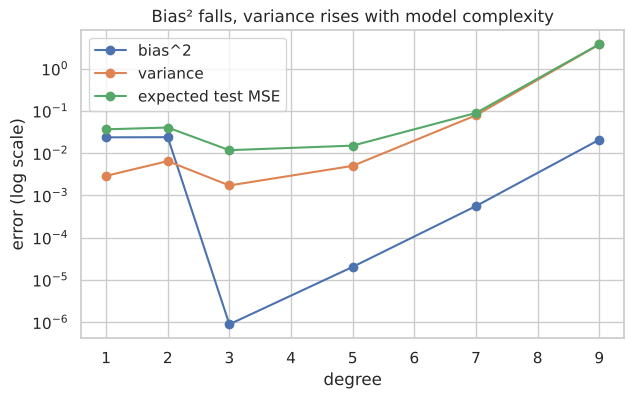

In [4]:
n_sims, grid = 300, np.linspace(-1, 1, 200).reshape(-1, 1)
sim_rng = np.random.default_rng(0)
degrees_sim = [1, 2, 3, 5, 7, 9]
preds = {d: np.empty((n_sims, len(grid))) for d in degrees_sim}

for s in range(n_sims):
    Xs, ys = make_data(30, sim_rng)
    for d in degrees_sim:
        preds[d][s] = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(Xs, ys).predict(grid).ravel()

rows = []
for d in degrees_sim:
    mean_pred = preds[d].mean(axis=0)
    bias2 = np.mean((mean_pred - f_true(grid).ravel()) ** 2)
    var = np.mean(preds[d].var(axis=0))
    rows.append((d, bias2, var, NOISE ** 2, bias2 + var + NOISE ** 2))
bv = pd.DataFrame(rows, columns=['degree', 'bias^2', 'variance', 'noise', 'expected test MSE']).set_index('degree')
display(bv.round(4))

ax = bv[['bias^2', 'variance', 'expected test MSE']].plot(marker='o', figsize=(7, 4), logy=True)
ax.set_title('Bias² falls, variance rises with model complexity'); ax.set_ylabel('error (log scale)'); plt.show()

**Reading the table.** A straight line (degree 1) has large bias² and small variance; from degree 3 up bias² is near zero (the truth is a cubic) and additional degrees only add variance, which grows by orders of magnitude at high degree because 30 random points leave gaps near the edges of the interval where the polynomial then swings wildly. Degree 3 gives the lowest expected error because it matches the true form; with real data we do not know the true form and must find the sweet spot with validation, as below.

## Summary: Bias and Variance

Think of a model like a student trying to learn a concept:

- **High Bias**: The student keeps repeating "the Earth is flat" no matter how much evidence you give, they have a rigid, oversimplified way of thinking. This is **underfitting**.
- **High Variance**: The student memorizes every single word of the textbook and even the printing mistakes. But give them a new question and they panic, this is **overfitting**.

The goal is a student who studies smartly — understands the real concept, doesn’t over-memorize, and can apply it to unseen problems.

That's what we try to build in machine learning too — a model that **generalizes well**, with the right **balance of bias and variance**.


# Overfitting and Underfitting



These two concepts describe how well a model fits the training data vs how well it generalizes to unseen data.

## Underfitting:
- Model is **too simple** to learn the underlying structure.
- Leads to **high bias**.
- Poor performance on both training and testing data.

## Overfitting:
- Model is **too complex**, fits even noise in the training data.
- Leads to **high variance**.
- Excellent performance on training data but poor generalization to test data.

### Quick Comparison:

| Criteria        | Underfitting            | Overfitting              |
|----------------|--------------------------|---------------------------|
| Model Complexity | Too Low                 | Too High                 |
| Bias            | High                    | Low                      |
| Variance        | Low                     | High                     |
| Training Error  | High                    | Low                      |
| Testing Error   | High                    | High                     |


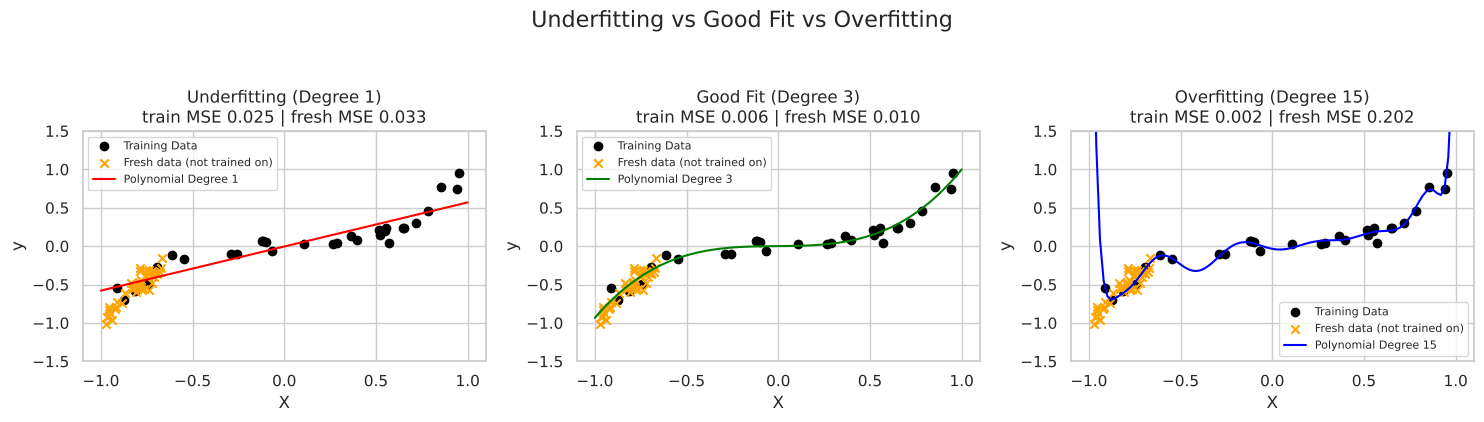

In [5]:
degrees = [1, 3, 15]
titles = ['Underfitting (Degree 1)', 'Good Fit (Degree 3)', 'Overfitting (Degree 15)']
colors = ['red', 'green', 'blue']

plt.figure(figsize=(15, 4))
for i, d in enumerate(degrees):
    model = make_pipeline(PolynomialFeatures(degree=d), LinearRegression()).fit(X, y)
    plt.subplot(1, 3, i+1)
    plt.scatter(X, y, color='black', label='Training Data')
    plt.scatter(X_val[:40], y_val[:40], color='orange', marker='x', label='Fresh data (not trained on)')
    plt.plot(X_plot, model.predict(X_plot), color=colors[i], label=f'Polynomial Degree {d}')
    plt.title(f"{titles[i]}\ntrain MSE {mean_squared_error(y, model.predict(X)):.3f} | "
              f"fresh MSE {mean_squared_error(y_val, model.predict(X_val)):.3f}")
    plt.xlabel("X"); plt.ylabel("y"); plt.ylim(-1.5, 1.5); plt.xlim(-1.1, 1.1)
    plt.legend(fontsize=8)

plt.suptitle("Underfitting vs Good Fit vs Overfitting", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

## Training vs Testing Accuracy

To detect overfitting or underfitting in practice, we often look at the **training vs testing accuracy/loss curves** as model complexity increases:

- If both accuracies are low → Underfitting.
- If training accuracy is high but testing is low → Overfitting.
- If both are high and close → Good generalization.

### Validation curve and learning curve

Both use **shuffled** k-fold. The data are sorted by `x`, so unshuffled folds would each be a contiguous slice of the x-range and cross-validation would measure *extrapolation* outside the training range instead of generalisation.

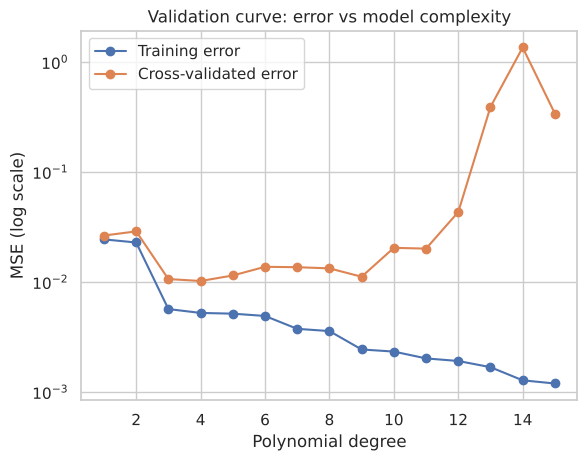

In [6]:
cv_shuf = KFold(n_splits=5, shuffle=True, random_state=42)
degs = np.arange(1, 16)
tr, va = validation_curve(make_pipeline(PolynomialFeatures(), LinearRegression()), X, y.ravel(),
                          param_name='polynomialfeatures__degree', param_range=degs,
                          cv=cv_shuf, scoring='neg_mean_squared_error')
plt.plot(degs, -tr.mean(axis=1), 'o-', label='Training error')
plt.plot(degs, -va.mean(axis=1), 'o-', label='Cross-validated error')
plt.yscale('log'); plt.xlabel('Polynomial degree'); plt.ylabel('MSE (log scale)')
plt.title('Validation curve: error vs model complexity'); plt.legend(); plt.show()

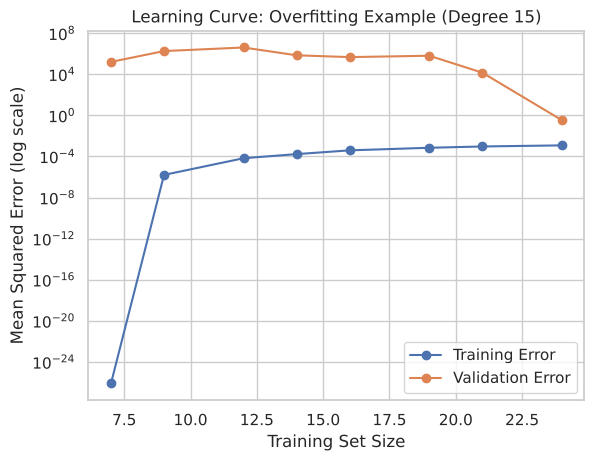

In [7]:
train_sizes, train_scores, test_scores = learning_curve(
    make_pipeline(PolynomialFeatures(degree=15), LinearRegression()),
    X, y.ravel(), cv=cv_shuf, scoring='neg_mean_squared_error',
    train_sizes=np.linspace(0.3, 1.0, 8)
)
plt.plot(train_sizes, -train_scores.mean(axis=1), 'o-', label='Training Error')
plt.plot(train_sizes, -test_scores.mean(axis=1), 'o-', label='Validation Error')
plt.yscale('log')
plt.xlabel('Training Set Size'); plt.ylabel('Mean Squared Error (log scale)')
plt.title('Learning Curve: Overfitting Example (Degree 15)')
plt.legend(); plt.show()

The gap between the two curves is the signature of high variance; it closes slowly as more training data is added. (Training sizes start at 30 % because a degree-15 polynomial cannot be fitted meaningfully to fewer than 16 points.)

## Summary: Overfitting vs Underfitting

Imagine you're preparing for a math exam:

- **Underfitting**: You only study addition and subtraction. When the exam comes, you're clueless about algebra or geometry. You didn’t learn enough.
- **Overfitting**: You memorize answers to 100 practice questions. But the actual exam asks 5 new ones — and you can’t solve them because you didn’t learn the concepts, just the answers.

The best student learns the concepts, practices reasonably, and doesn't panic in a new situation.

Machine learning models are the same, we want them to **understand patterns**, not memorize data.


# Ensemble Learning: Bagging, Random Forests, and Boosting (Gradient Boosting)


In this notebook, we will explore three powerful ensemble learning techniques:

1. **Bagging (Bootstrap Aggregating)**
2. **Random Forests**
3. **Boosting (Gradient Boosting)**

We will cover:
- Conceptual understanding
- Mathematical foundation
- Practical implementation using Python (`sklearn`)
- Visualizations and performance evaluation

Dataset used: **Breast Cancer Wisconsin Diagnostic Dataset**


## 1. Bagging: Bootstrap Aggregating



**Bagging** is an ensemble method that aims to reduce the variance of a model by creating multiple subsets of the data using **bootstrap sampling** (sampling with replacement). Each model is trained independently on a different subset, and their outputs are aggregated.

### Why Bagging Works?
- Reduces variance without increasing bias.
- Useful for high-variance models like **Decision Trees**.

### Aggregation:
- **Classification**: Majority Voting
- **Regression**: Averaging

### Mathematically:
Suppose we have B models $\{h_1(x), h_2(x), ..., h_B(x)\}$ trained on B different bootstrapped datasets.
- Final prediction for classification: $\hat{y} = \text{mode}(h_1(x), ..., h_B(x))$
- For regression: $\hat{y} = \frac{1}{B} \sum_{b=1}^{B} h_b(x)$

### Variance Reduction:
If base learners are i.i.d. with variance $\sigma^2$, Bagging reduces variance to $\frac{\sigma^2}{B}$.
If they are correlated with pairwise correlation $\rho$, the variance becomes:
$$
\text{Var}_{\text{Bag}} = \rho\sigma^2 + \frac{1 - \rho}{B} \sigma^2
$$

Lower correlation → greater variance reduction.


In [8]:
# Load and prepare the data
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Stratified train-test split; the test set is used once, at the end
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Decision trees are invariant to feature scaling, so no scaler is used: it would change nothing and would only add a step that has to be fitted correctly.

### Single tree vs Bagging vs baseline

The comparison is done with **repeated stratified CV on the training data**. Bagging is expected to raise the mean; the `std` column shows the fold-to-fold spread, which is a noisy estimate itself and should not be over-read.

In [9]:
base_tree = DecisionTreeClassifier(random_state=42)
bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=100, bootstrap=True, random_state=42, n_jobs=-1)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0)
rows = {}
for name, m in {'majority baseline': DummyClassifier(strategy='most_frequent'),
                'single decision tree': base_tree,
                'bagging (100 trees)': bagging_clf}.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy')
    rows[name] = {'mean acc': s.mean(), 'std': s.std()}
pd.DataFrame(rows).T.round(4)

,mean acc,std
majority baseline,0.6264,0.0000
single decision tree,0.9292,0.0162
bagging (100 trees),0.9530,0.0232


In [10]:
# Fit on the training set and evaluate once on the test set
bagging_clf.fit(X_train, y_train)
y_pred = bagging_clf.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Test accuracy: 0.9386
              precision    recall  f1-score   support

           0       0.93      0.90      0.92        42
           1       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



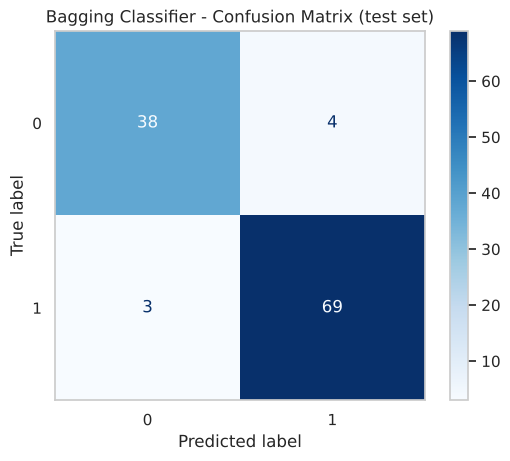

In [11]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=bagging_clf.classes_)
disp.plot(cmap='Blues')
plt.title("Bagging Classifier - Confusion Matrix (test set)")
plt.grid(False)
plt.show()

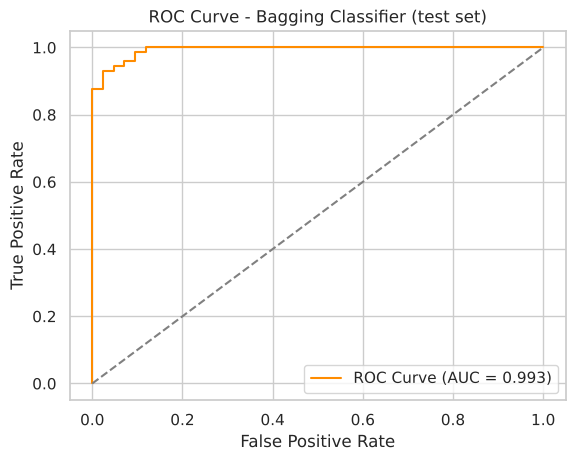

In [12]:
y_score_bag = bagging_clf.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_score_bag)
roc_auc = roc_auc_score(y_test, y_score_bag)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title('ROC Curve - Bagging Classifier (test set)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

### Interpretation: Bagging Classifier

- **Accuracy**: Shows the overall correct predictions on test set.
- **Confusion Matrix**: Helps us identify **type of errors**, e.g., false positives vs false negatives.
- **ROC AUC Score**: AUC closer to 1 means high separability between classes.

> Bagging helps reduce **variance**, making it effective for models like decision trees that are unstable by nature.


## Summary: Bagging

Imagine you want to ask for movie recommendations.

- If you ask just one friend, they might give a biased answer.
- But if you ask **10 friends**, each with their own taste, and take a **majority vote**, you’ll probably end up with a more balanced recommendation.

Bagging is like that:
- Train 10 different models on **randomly selected portions of the data**.
- Combine their predictions through voting (for classification) or averaging (for regression).

Bagging reduces the risk of trusting just one biased or overfitting model. It's like taking the **wisdom of the crowd**.


## Methodology notes

- **Synthetic section:** bias and variance are measured against the *known* function. On real data they cannot be separated this way; validation/learning curves are the practical proxy.
- **Cross-validation order:** data sorted along the feature axis must be shuffled before k-fold, otherwise CV measures extrapolation.
- **Real-data section:** stratified split, tree-based models without scaling, comparison with a baseline and a single tree using repeated CV (mean ± std). The test set is read once.
- **Limits:** one dataset (breast cancer is easy, so gaps between single tree and bagging are only a few points); the bagging benefit is more pronounced on noisier data.